## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vivian Le
**Date:** 10/13/2026

In [1]:
# Phase 1 Question 1, #1:

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


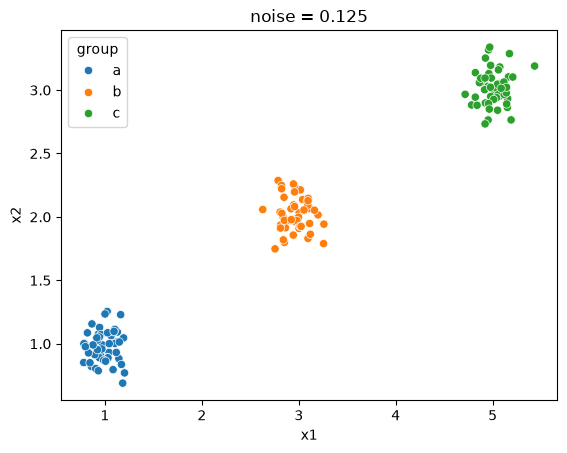

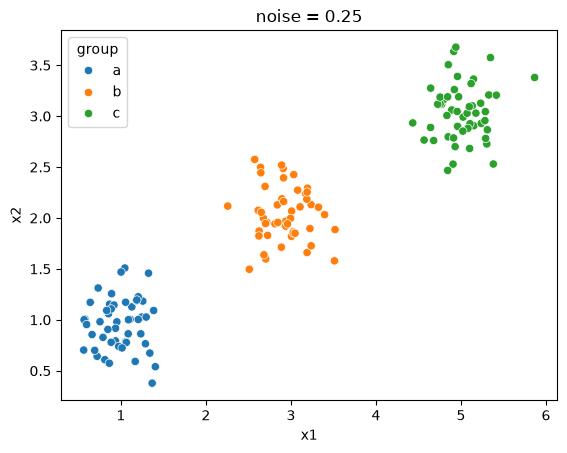

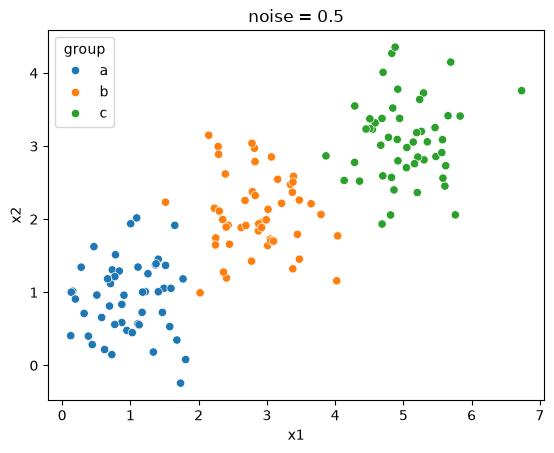

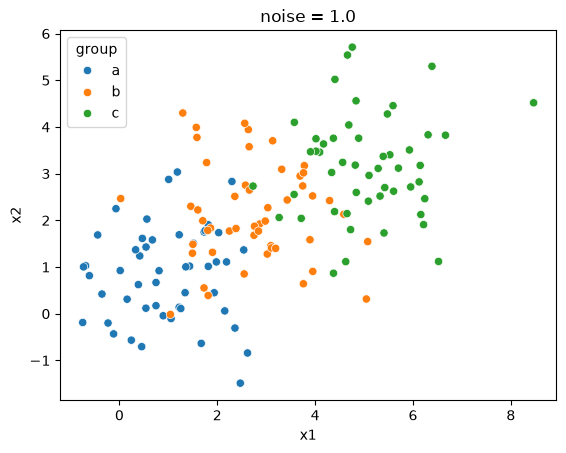

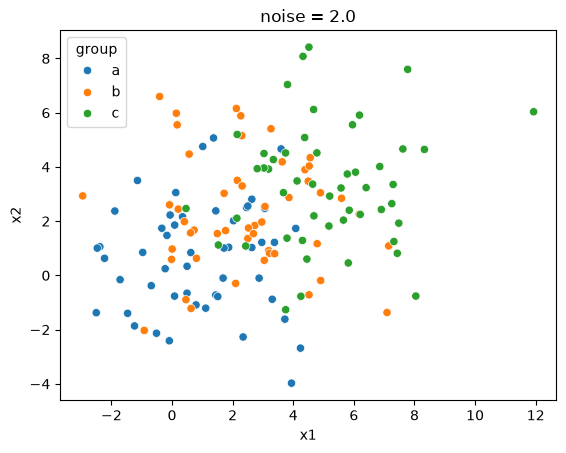

In [2]:
# Question 1, #2:

import matplotlib.pyplot as plt
import seaborn as sns

datasets = {'0.125': df0_125, '0.25': df0_25, '0.5': df0_5, '1.0': df1_0, '2.0': df2_0}

for name, df in datasets.items():
    sns.scatterplot(data=df, x='x1', y='x2', hue='group').set(title=f'noise = {name}')
    plt.show()

Question 1, #2:

The clusters become less visually distinguishable as the amount of noise increases. At noise level of 0.125 and 0.25, the three clusters with centers at coordinates (1,1), (3,2) and (5,3) respectively are compact blobs and can be separated by eye even without coloring them. The clusters are separable at noise value of 0.5 although they begin approaching each other at the borders. With noise value of 1.0, the clusters overlap significantly and it is difficult to determine where one cluster finishes and the other begins. At 2.0, the points form one big diagonal cluster with all clusters thoroughly mixed together. It is due to the fact that noise, or the standard deviation, is getting relatively larger compared to the distance between clusters.

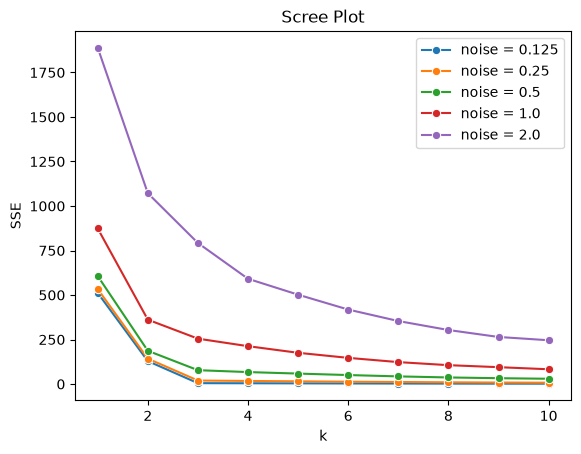

In [3]:
# Question 1, #3:

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
for name, df in datasets.items():
    X = df[['x1', 'x2']]
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, marker='o', label=f'noise = {name}')

plt.title('Scree Plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

Question 1, #3:

Noise 0.125 and 0.25: There is a very distinct elbow at k = 3. The SSE decreases from about 129 to about 5 (noise 0.125) and from about 143 to about 20 (noise 0.25), as we move from k = 2 to k = 3. Afterwards, the curve levels off. The choice of k = 3 is practically unquestionable.

Noise 0.5: The elbow is still located at k = 3, but is less distinct than before. The decrease from k = 2 to 3 is about 109, whereas the decrease from k = 3 to 4 is only about 11. The choice of k = 3 is possible, though less distinct.

Noise 1.0: Smoother curves have been obtained. The steepest point occurs at k = 2. However, the difference between k = 2 and 3 is still high, which is 107 compared to k = 3 and 4, which is about 42. It is not clear now whether k = 2 or k = 3 should be chosen.

Noise 2.0: There is no real elbow. The SSE declines in large, gradually shrinking steps of about 817, 280, 201, and 89, so there is no principled reason to choose any particular k.

Vertical axis scaling is important too. Because all the curves share the same axes, the noise 2.0 curve squeezes the curves for lower noise levels close to zero. The elbow at k = 3 is still visible but looks less noticeable. For example, the SSE decreases from 129 to 5 when noise equals 0.125, showing a 96% reduction in SSE value. When k = 3, the minimum and maximum values of SSE are approximately 5 (when noise = 0.125) and 792 (noise = 2.0). While interpreting the graphs, hence, we must take into account the shape of the graph rather than its height. From their shapes, the sudden bend for k = 3 tends to become smoother as the noise is increased.

Question 1, #4:

The sum of squared error (inertia) shows how far the points are from the centroid of their cluster, and each increase of the number of clusters decreases it. The problem is about the size of such improvement. When k < the number of clusters (1 --> 2 --> 3 here), each extra cluster means separation of groups that are different anyway. The centroid located between the groups will be replaced with the centroids of both groups, so the decrease of SSE will be very steep (for example, 512 --> 129 -->5 at noise 0.125). When k equals the number of clusters (3), all the centroids are already located at the centers of the groups. The next (fourth) centroid will divide the group in half, reducing the within-group noise. This is the elbow of the graph where we go from big gains (which correspond to getting the real structure) to little gains (which correspond to just breaking up noise), and it tells us how to identify the real value of k. This is possible only if the distance between the clusters is greater than the width of the cluster itself. At noise = 2.0, the width of the cluster is close to the distance between the centers, so breaking up real clusters saves as much as breaking up noise, and the elbow disappears.


In [4]:
# Question 2, #1:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020]
df = df.dropna()
print(df.shape)
df.describe()

(148, 7)


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


Question 2, #1:

There are 148 countries after filtering to 2020 and removing all missing values. All of the numeric columns are already stored as numbers, but a few things are worth noting. The index column is not useful for clustering because it is just a row number, and the Year column is the same for every row since it is always 2020. Percent of GDP and Percent of Government Spending are stored as proportions rather than percentages, so a value of 0.0153 means 1.53%. Spending in 2020 USD appears to be measured in millions of dollars, since the US value is 778,397, which is about $778 billion. The spending variables are also strongly right-skewed. The median country spends about $960 million, while the US spends about $778 billion, which makes the US a huge outlier. Because max-min normalization divides by the range, the US will push almost every other country close to zero on this variable. There are also some suspicious values, such as Zimbabwe spending only about 0.0054% of its GDP. Overall, no additional cleaning is needed to run the analysis, but the outliers and units should be kept in mind when interpreting the results.

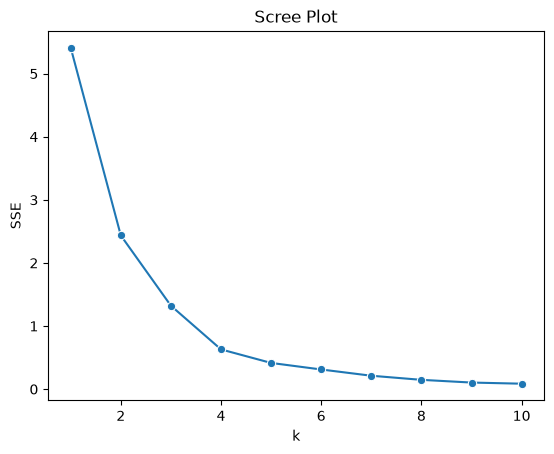

In [5]:
# Question 2, #2:

features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()


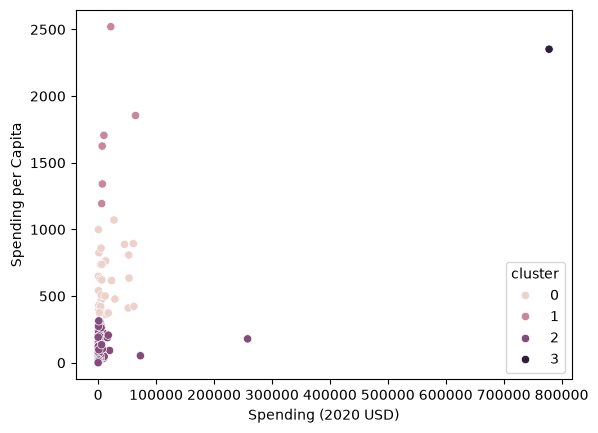

                       Country  cluster
5540  United States of America        3
0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gamb

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

In [6]:
#Question 2, #2:

model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])
for c in sorted(df['cluster'].unique()):
    print(c, list(df.loc[df['cluster'] == c, 'Country']))

df.groupby('cluster')[features].describe()

Question 2, #2:

It can be observed from the plot that the SSE decreases from around 5.41 to 2.44, then to 1.32, then to 0.63, and finally to 0.42. The SSE continues to drop sharply until k = 4, after which the reductions are small; hence, my choice of k = 4. Cluster 3 contains only one country, the United States. It has a total expenditure of about $778 billion, which is about three times as much as China, and it spends about $2,350 per capita. Cluster 1 contains six countries with very high per capita expenditure: Saudi Arabia, Israel, Singapore, Norway, Kuwait, and Oman. This cluster has an average per capita expenditure of about $1,700. Cluster 0 contains 30 rich countries with moderate to high per capita expenditure, which include the UK, Germany, France, Japan, South Korea, Australia, Canada, and Russia. This group has an average expenditure of about $610 per capita. Cluster 2 contains the remaining 111 countries, which make up most of the world, including China and India. This group has an average expenditure of only about $80 per capita. The US is in a cluster by itself. Because max-min normalization divides by the range, the US pushes the total spending of all other countries to nearly zero, which makes the clustering of all other countries determined almost entirely by spending per capita. This explains why China, which spends approximately $258 billion, belongs to the same cluster as countries with extremely small budgets. The primary pattern is that spending per capita distinguishes rich countries from poor ones, whereas total spending only distinguishes the US from all other countries.

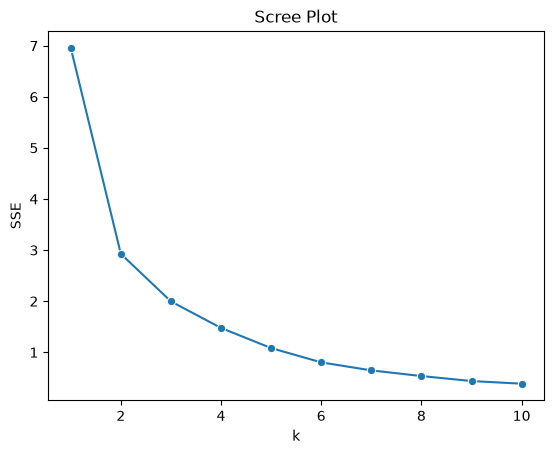

In [7]:
# Question 2, #3:

features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc [:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks 
]
sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

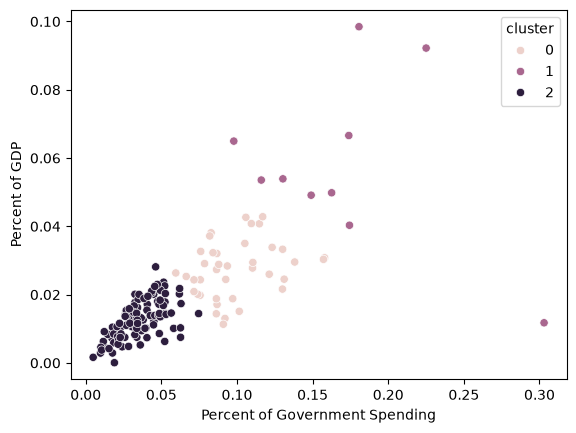

                       Country  cluster
5540  United States of America        0
0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', '

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [8]:
# Question 2, #3:

model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])
for c in sorted(df['cluster'].unique()):
    print(c, list(df.loc[df['cluster'] == c, 'Country']))
df.groupby('cluster')[features].describe()

Question 2, #3:

The SSE values reduce from 6.95 to 2.92 to 2.00 to 1.47 until it plateaus at k = 3, and hence I have chosen k = 3 (k = 2 could also be used). The clusters now sort countries by military burden rather than wealth. Cluster 1 (10 countries: Israel, Saudi Arabia, Oman, Kuwait, Jordan, Algeria, Armenia, Azerbaijan, Belarus, Pakistan) has the highest burden, about 17% of government spending and 5.8% of GDP. Cluster 0 (39 countries, including Russia, India, South Korea, Iran, and Ukraine) is medium, at about 9.9% and 2.7%. Cluster 2 (99 countries) is lowest, at about 3.6% and 1.3%. The United States is in the medium cluster 0, so despite its huge budget, its spending is not unusual relative to its economy. High-burden countries are concentrated in the Middle East and conflict regions, while most of Europe and Latin America have a low burden. Compared to #2, the clusters are largely reshuffled. Since percentages don’t account for either the size or wealth of the country, America is not an anomaly anymore and wealthy nations such as Germany, France, Japan, Great Britain, and Norway form the same cluster as poor nations such as Malawi and Haiti. Only Israel, Saudi Arabia, Oman, and Kuwait remain in the upper cluster in both parts because of their high spending on military both in terms of per capita and percentages of GDP. The scatterplot reveals a continuous diagonal pattern rather than a solitary anomaly.

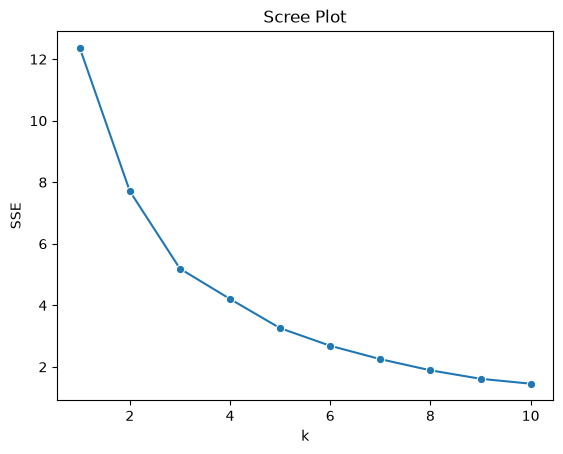

In [9]:
# Question 2, #4:

features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

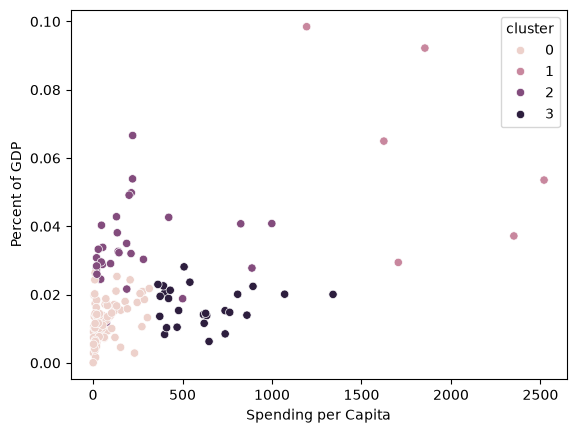

                       Country  cluster
5540  United States of America        1
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Bangladesh', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Jamaica', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Nicaragua', 'Niger', 'Nigeria', 'North Macedonia', 'Papua New Guinea', 'Paraguay', 'Peru', 'Philippines', 'Romania', 'Rwanda', 'Senegal', 'Serbia', 'Seychelles', 'Sierra Leone', 'Slovenia', 'South

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      30.0    9073.543709   18135.032885   163.926877   
3                      26.0   15330.618681   18923.469359   405.790494   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         522.737081   1663.090134   8646.648849   72937.064048   
3        3176.345598   5857.060906  21818.934764   60675.039625   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      86.0    70.290644  ...                       0.053006   
1                       6.0  1875.150751  ...                       0.164503   
2                      30.0   215.920971  ...                       0.136403   
3                      26.0   612.677541  ...                       0.044645   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
3        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   

                                       
              50%       75%       max  
cluster                                
0        0.012532  0.016783  0.026340  
1        0.059257  0.085398  0.098470  
2        0.032148  0.040637  0.066600  
3        0.015324  0.020431  0.028132  

[4 rows x 32 columns]

In [10]:
# Question 2, #4:

model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Spending per Capita', y='Percent of GDP', hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])
for c in sorted(df['cluster'].unique()):
    print(c, list(df.loc[df['cluster'] == c, 'Country']))

df.groupby('cluster')[features].describe()

Question 2, #4:

In the plot of SSE, we can see that SSE decreases from 12.37, to 7.71, to 5.19, to 4.21, and finally to 3.26. However, the graph does not have a distinct elbow point. The drops become noticeably smaller after k equals 3 or 4, so I chose k equals 4. With four variables, the elbow is the least clear of the three parts. The clusters combine the ideas from #2 and #3. Cluster 1 contains six countries that are high in both spending and burden: the United States, Saudi Arabia, Israel, Singapore, Kuwait, and Oman. These countries spend an average of about $1,875 per person and about 6.3% of their GDP on the military. Cluster 3 contains 26 wealthy countries with a low military burden, mostly in Western Europe along with allies such as the United Kingdom, Germany, France, Japan, Italy, Australia, and Canada. These countries spend a fairly high amount per person, about $610 on average, but only about 1.7% of their GDP. Cluster 2 contains 30 militarized or security-focused countries, including India, Russia, South Korea, Iran, Taiwan, Pakistan, Algeria, and Ukraine. These countries spend a large share of their government budget, about 12%, and about 3.4% of their GDP on the military, but they spend less per person. Cluster 0 contains the remaining 86 countries, which spend little on every measure. This group includes China, Brazil, Mexico, and much of Africa and Latin America. Compared to the previous parts, the United States is no longer in a cluster by itself as it was in #2, and it is no longer just in the medium group as it was in #3. Instead, it is grouped with other countries that are high in both money and military burden. Because total spending is now only one of four equally weighted variables, the United States outlier has much less influence, and the clusters are more balanced and easier to interpret. The downside is that the elbow is weaker, so the choice of k is more of a judgment call.

Question 2, #5:

Yes, partly. The k means algorithm found meaningful groupings in the data. It separated the United States as an extreme outlier in total spending, it separated wealthy countries from poorer ones using spending per capita, and it identified a group of countries with a high military burden using the percentage variables. Most of those high burden countries are in the Middle East or are involved in regional conflicts. With the use of all four variables it led to clusters that made sense, such as wealthy allies with low military burdens and militarized states with high military burdens. However, the findings need to be treated with caution. They relied heavily on which variables were chosen. In addition, the United States was such an extreme outlier that it took control of the max min normalization of total spending, which pushed almost every other country close to zero. The elbows were not always so obvious, particularly in #3 and #4, so the choice of k was partly subjective. Certain nations such as China were also categorized in clusters which obscured significant distinctions among them from the rest of the members in that cluster. On the whole, k means analysis was helpful in understanding the data, but the clusters characterize the data instead of providing any evidence for the existence of real-world categories.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 95a9f0ba116034e8367f96b71d1341f1bc0156e4
- **AI tool and model used:** Chat GPT-5.6 Sol

### *Prompts used

1. Here's my Q1 and 2 code, run it and check for missing values, correctness, and  anything that could be improved but do not rewrite it.
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Overall, your Q1 and Q2 code looks correct and follows the assignment instructions. No major changes are needed.
2. Q1 code runs successfully, and its SSE calculations and numerical values are correct. Q2 code appears correct, but the results still require the dataset for verification.
3. Your explanations of increasing noise and the elbow method are accurate.

**What should you fix?**
1. Q2 #3: Reconsider the claim that SSE plateaus at k = 3.
2. Q2 #4: Clarify that normalized variables don't necessarily contribute equally.
3. Q1 #4: Soften the absolute statement about cluster separation.

**Bottom line:** Your code is well structured, and your explanations are mostly accurate. The improvements are primarily wording-related.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1: Reconsider the claim that SSE plateaus at k=3 | Accept | The SSE does not become constant at k = 3. It continues to fall, and the sharpest bend is at k = 2. So while choosing k = 3 is not incorrect, it needs a justification based on interpretation, since the curve has no plateau. Using the scree plot, I took the SSE values for k = 1 to 5 (6.95, 2.92, 2.00, 1.47, and 1.08) and calculated the differences between consecutive values: 4.03, 0.92, 0.53, and 0.39. This shows a steady decline with no plateau starting at k = 3. |
| 2: Clarify that normalized variables don't necessarily contribute equally | Accept | Max-min normalization puts every variable on a 0 to 1 scale, but a variable’s influence on k-means depends on its spread. Because the US defines the maximum for total spending, almost every other country’s normalized value is near 0, so that variable mainly separates the US. Using the Part 2 describe table, the median spending of the 111 countries in the largest cluster is about 382, which normalizes to 382 / 778,397 ≈ 0.0005. Even China, at about 258,000, only reaches about 0.33. Running X.var() on the normalized four-variable data shows that total spending has a variance of about 0.0076, roughly three to four times lower than the other three variables (0.023 to 0.029). |
| 3: Soften the absolute statement about cluster separation.| Accept | “Only if” suggests an absolute cut-off point, but the elbow becomes increasingly less obvious as the spread of the clusters becomes close to the distance between them. The closest centers of the clusters, (1,1) and (3,2), are about 2.24 units apart. In the case of noise 1.0, the spread (standard deviation 1) is less than half of that distance, and the drops from k = 1 to 4 were about 512, 107, and 42, which results in a weak but noticeable elbow. In the case of noise 2.0, standard deviation 2 is approximately equal to the distance between the centers, and the drops for k = 1 to 5 were about 817, 280, 201, and 89 respectively, without an elbow. Hence, as the elbow becomes less and less visible step by step but does not disappear immediately, it is better to claim that the elbow is clearly visible when the separation is significantly larger than the dispersion. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [11]:
# Phase 2 Question 1, #1:

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

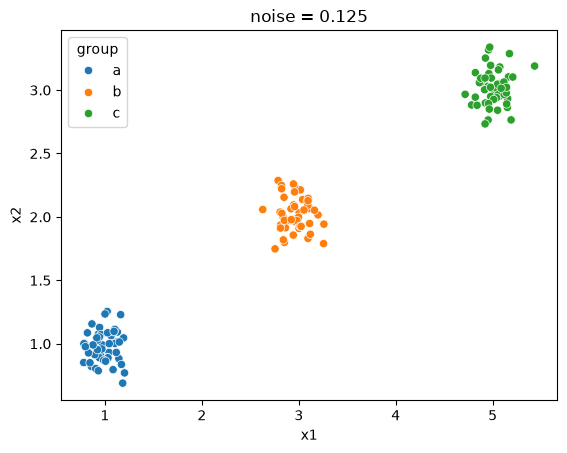

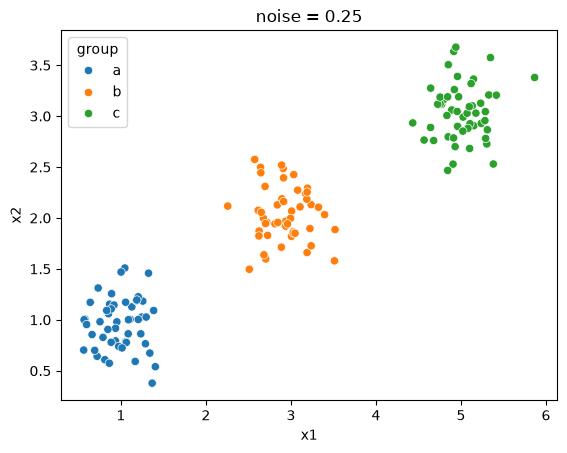

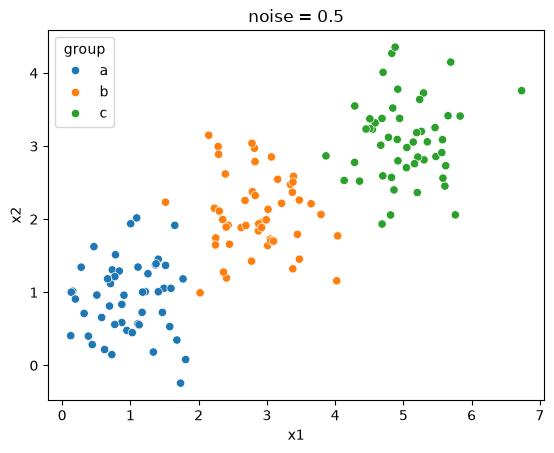

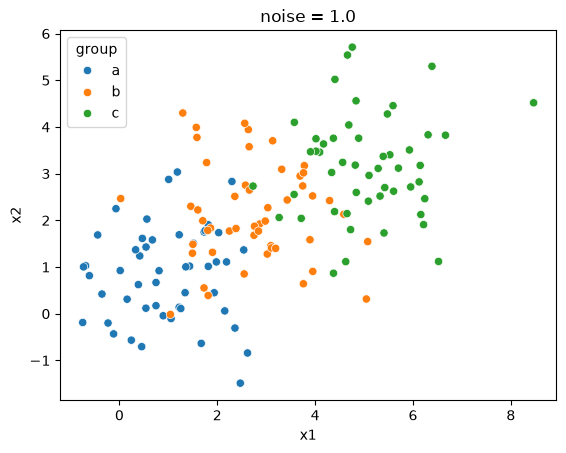

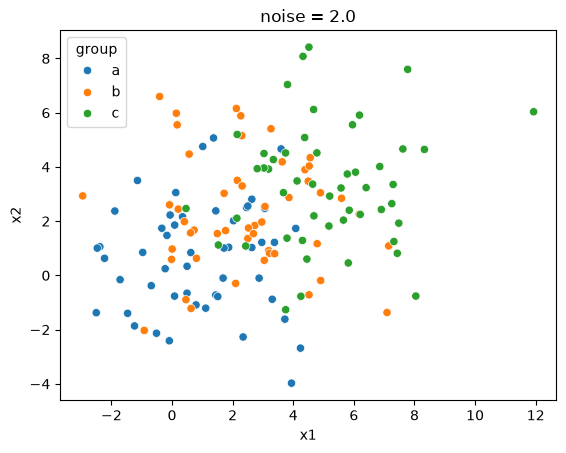

In [12]:
# Question 1, #2:

import matplotlib.pyplot as plt
import seaborn as sns

datasets = {'0.125': df0_125, '0.25': df0_25, '0.5': df0_5, '1.0': df1_0, '2.0': df2_0}

for name, df in datasets.items():
    sns.scatterplot(data=df, x='x1', y='x2', hue='group').set(title=f'noise = {name}')
    plt.show()

Question 1, #2:

The clusters become less visually distinguishable as the amount of noise increases. At noise level of 0.125 and 0.25, the three clusters with centers at coordinates (1,1), (3,2) and (5,3) respectively are compact blobs and can be separated by eye even without coloring them. The clusters are separable at noise value of 0.5 although they begin approaching each other at the borders. With noise value of 1.0, the clusters overlap significantly and it is difficult to determine where one cluster finishes and the other begins. At 2.0, the points form one big diagonal cluster with all clusters thoroughly mixed together. It is due to the fact that noise, or the standard deviation, is getting relatively larger compared to the distance between clusters.

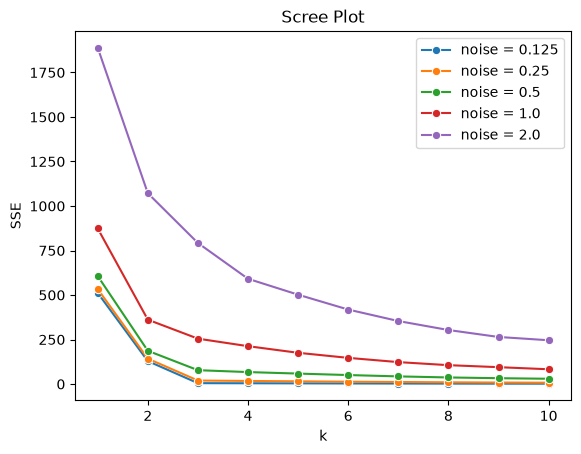

In [13]:
# Question 1, #3:

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
for name, df in datasets.items():
    X = df[['x1', 'x2']]
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, marker='o', label=f'noise = {name}')

plt.title('Scree Plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

Question 1, #3:

Noise 0.125 and 0.25: There is a very distinct elbow at k = 3. The SSE decreases from about 129 to about 5 (noise 0.125) and from about 143 to about 20 (noise 0.25), as we move from k = 2 to k = 3. Afterwards, the curve levels off. The choice of k = 3 is practically unquestionable.

Noise 0.5: The elbow is still located at k = 3, but is less distinct than before. The decrease from k = 2 to 3 is about 109, whereas the decrease from k = 3 to 4 is only about 11. The choice of k = 3 is possible, though less distinct.

Noise 1.0: Smoother curves have been obtained. The steepest point occurs at k = 2. However, the difference between k = 2 and 3 is still high, which is 107 compared to k = 3 and 4, which is about 42. It is not clear now whether k = 2 or k = 3 should be chosen.

Noise 2.0: There is no real elbow. The SSE declines in large, gradually shrinking steps of about 817, 280, 201, and 89, so there is no principled reason to choose any particular k.

Vertical axis scaling is important too. Because all the curves share the same axes, the noise 2.0 curve squeezes the curves for lower noise levels close to zero. The elbow at k = 3 is still visible but looks less noticeable. For example, the SSE decreases from 129 to 5 when noise equals 0.125, showing a 96% reduction in SSE value. When k = 3, the minimum and maximum values of SSE are approximately 5 (when noise = 0.125) and 792 (noise = 2.0). While interpreting the graphs, hence, we must take into account the shape of the graph rather than its height. From their shapes, the sudden bend for k = 3 tends to become smoother as the noise is increased.

Question 1, #4:

The sum of squared error (inertia) shows how far the points are from the centroid of their cluster, and each increase of the number of clusters decreases it. The problem is about the size of such improvement. When k < the number of clusters (1 --> 2 --> 3 here), each extra cluster means separation of groups that are different anyway. The centroid located between the groups will be replaced with the centroids of both groups, so the decrease of SSE will be very steep (for example, 512 --> 129 --> 5 at noise 0.125). When k equals the number of clusters (3), all the centroids are already located at the centers of the groups. The next (fourth) centroid will divide the group in half, reducing the within-group noise. This is the point on the graph where we shift from large drops (which indicate that real cluster structure is being captured) to small drops (which indicate that the data was merely split into noise). This elbow is more pronounced when the distance between the clusters is large relative to the spread, and becomes less pronounced as the spread gets closer to the distance. When noise = 1.0, there is considerable overlap between the clusters, yet an elbow can still be observed. However, at noise = 2.0, the spread is close to the distance, hence splitting a true cluster will decrease the SSE by about the same amount as splitting noise, so the elbow essentially disappears.

In [14]:
# Question 2, #1:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020]
df = df.dropna()
print(df.shape)
df.describe()

(148, 7)


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


Question 2, #1:

There are 148 countries after filtering to 2020 and removing all missing values. All of the numeric columns are already stored as numbers, but a few things are worth noting. The index column is not useful for clustering because it is just a row number, and the Year column is the same for every row since it is always 2020. Percent of GDP and Percent of Government Spending are stored as proportions rather than percentages, so a value of 0.0153 means 1.53%. Spending in 2020 USD appears to be measured in millions of dollars, since the US value is 778,397, which is about $778 billion. The spending variables are also strongly right-skewed. The median country spends about $960 million, while the US spends about $778 billion, which makes the US a huge outlier. Because max-min normalization divides by the range, the US will push almost every other country close to zero on this variable. There are also some suspicious values, such as Zimbabwe spending only about 0.0054% of its GDP. Overall, no additional cleaning is needed to run the analysis, but the outliers and units should be kept in mind when interpreting the results.

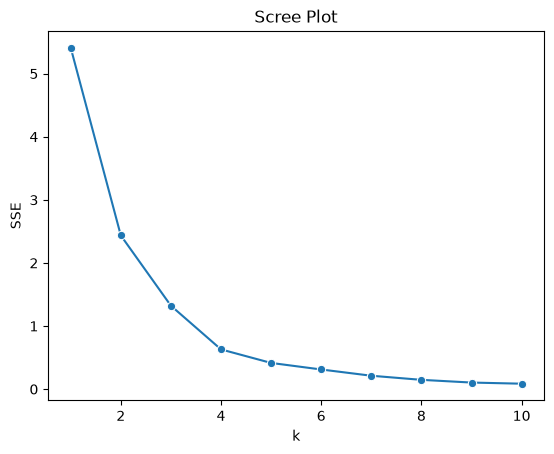

In [15]:
# Question 2, #2:

features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()


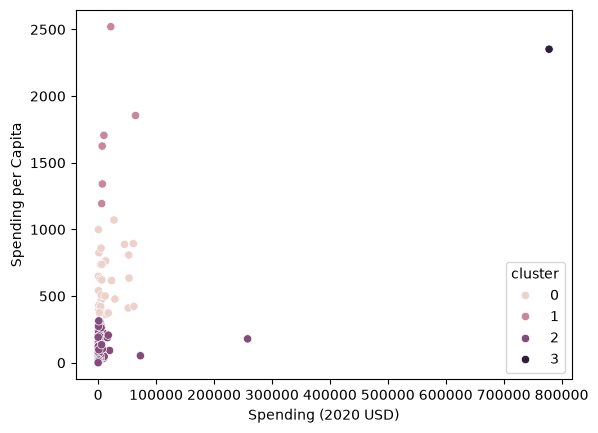

                       Country  cluster
5540  United States of America        3
0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gamb

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

In [16]:
#Question 2, #2:

model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])
for c in sorted(df['cluster'].unique()):
    print(c, list(df.loc[df['cluster'] == c, 'Country']))

df.groupby('cluster')[features].describe()

Question 2, #2:

It can be observed from the plot that the SSE decreases from around 5.41 to 2.44, then to 1.32, then to 0.63, and finally to 0.42. The SSE continues to drop sharply until k = 4, after which the reductions are small; hence, my choice of k = 4. Cluster 3 contains only one country, the United States. It has a total expenditure of about $778 billion, which is about three times as much as China, and it spends about $2,350 per capita. Cluster 1 contains six countries with very high per capita expenditure: Saudi Arabia, Israel, Singapore, Norway, Kuwait, and Oman. This cluster has an average per capita expenditure of about $1,700. Cluster 0 contains 30 rich countries with moderate to high per capita expenditure, which include the UK, Germany, France, Japan, South Korea, Australia, Canada, and Russia. This group has an average expenditure of about $610 per capita. Cluster 2 contains the remaining 111 countries, which make up most of the world, including China and India. This group has an average expenditure of only about $80 per capita. The US is in a cluster by itself. Because max-min normalization divides by the range, the US pushes the total spending of all other countries to nearly zero, which makes the clustering of all other countries determined almost entirely by spending per capita. This explains why China, which spends approximately $258 billion, belongs to the same cluster as countries with extremely small budgets. The primary pattern is that spending per capita distinguishes rich countries from poor ones, whereas total spending only distinguishes the US from all other countries.

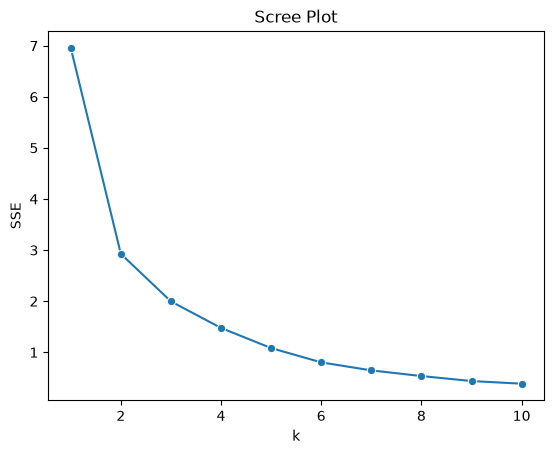

In [17]:
# Question 2, #3:

features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

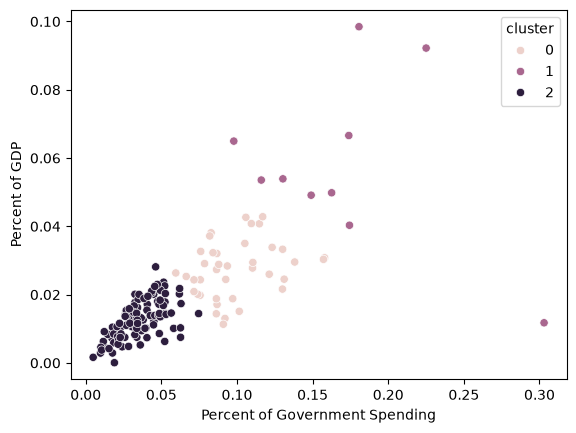

                       Country  cluster
5540  United States of America        0
0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', '

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [18]:
# Question 2, #3:

model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])
for c in sorted(df['cluster'].unique()):
    print(c, list(df.loc[df['cluster'] == c, 'Country']))
df.groupby('cluster')[features].describe()

Question 2, #3:

The values of the SSE fall off from 6.95 to 2.92 to 2.00 to 1.47 to 1.08. The greatest fall occurs at k = 1 to 2, and then thereafter the SSE continues to fall slowly without reaching any plateau level. I chose k = 3 because it separates a medium-burden group that k = 2 would merge with the low-burden countries, which makes the clusters easier to interpret. The clusters now sort countries by military burden rather than wealth. Cluster 1 (10 countries: Israel, Saudi Arabia, Oman, Kuwait, Jordan, Algeria, Armenia, Azerbaijan, Belarus, Pakistan) has the highest burden, about 17% of government spending and 5.8% of GDP. Cluster 0 (39 countries, including Russia, India, South Korea, Iran, and Ukraine) is medium, at about 9.9% and 2.7%. Cluster 2 (99 countries) is lowest, at about 3.6% and 1.3%. The United States is in the medium cluster 0, so despite its huge budget, its spending is not unusual relative to its economy. High-burden countries are concentrated in the Middle East and conflict regions, while most of Europe and Latin America have a low burden. Compared to #2, the clusters are largely reshuffled. Since percentages don't account for either the size or wealth of the country, America is not an anomaly anymore and wealthy nations such as Germany, France, Japan, Great Britain, and Norway form the same cluster as poor nations such as Malawi and Haiti. Only Israel, Saudi Arabia, Oman, and Kuwait remain in the upper cluster in both parts because of their high spending on military both in terms of per capita and percentages of GDP. The scatterplot reveals a continuous diagonal pattern rather than a solitary anomaly.

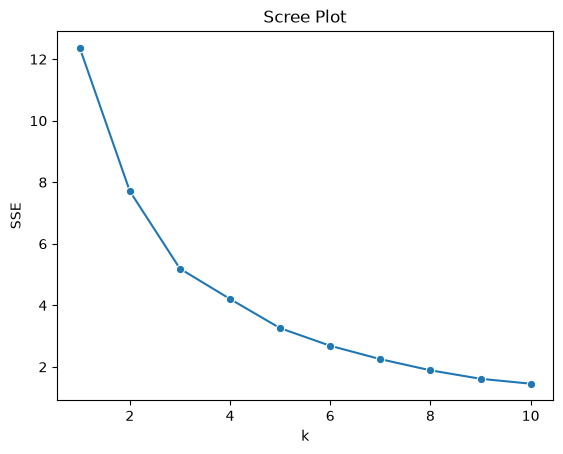

In [19]:
# Question 2, #4:

features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

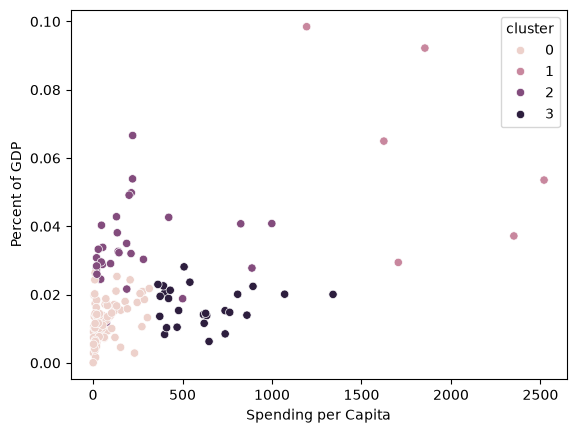

                       Country  cluster
5540  United States of America        1
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Bangladesh', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Jamaica', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Nicaragua', 'Niger', 'Nigeria', 'North Macedonia', 'Papua New Guinea', 'Paraguay', 'Peru', 'Philippines', 'Romania', 'Rwanda', 'Senegal', 'Serbia', 'Seychelles', 'Sierra Leone', 'Slovenia', 'South

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      30.0    9073.543709   18135.032885   163.926877   
3                      26.0   15330.618681   18923.469359   405.790494   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         522.737081   1663.090134   8646.648849   72937.064048   
3        3176.345598   5857.060906  21818.934764   60675.039625   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      86.0    70.290644  ...                       0.053006   
1                       6.0  1875.150751  ...                       0.164503   
2                      30.0   215.920971  ...                       0.136403   
3                      26.0   612.677541  ...                       0.044645   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
3        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   

                                       
              50%       75%       max  
cluster                                
0        0.012532  0.016783  0.026340  
1        0.059257  0.085398  0.098470  
2        0.032148  0.040637  0.066600  
3        0.015324  0.020431  0.028132  

[4 rows x 32 columns]

In [20]:
# Question 2, #4:

model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Spending per Capita', y='Percent of GDP', hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])
for c in sorted(df['cluster'].unique()):
    print(c, list(df.loc[df['cluster'] == c, 'Country']))

df.groupby('cluster')[features].describe()

In [23]:
X.var()

Spending (2020 USD)               0.007633
Spending per Capita               0.029179
Percent of Government Spending    0.024022
Percent of GDP                    0.023332
dtype: float64

Question 2, #4:

In the plot of SSE, we can see that SSE decreases from 12.37, to 7.71, to 5.19, to 4.21, and finally to 3.26. However, the graph does not have a distinct elbow point. The drops become noticeably smaller after k equals 3 or 4, so I chose k equals 4. With four variables, the elbow is the least clear of the three parts. The clusters combine the ideas from #2 and #3. Cluster 1 contains six countries that are high in both spending and burden: the United States, Saudi Arabia, Israel, Singapore, Kuwait, and Oman. These countries spend an average of about $1,875 per person and about 6.3% of their GDP on the military. Cluster 3 contains 26 wealthy countries with a low military burden, mostly in Western Europe along with allies such as the United Kingdom, Germany, France, Japan, Italy, Australia, and Canada. These countries spend a fairly high amount per person, about $610 on average, but only about 1.7% of their GDP. Cluster 2 contains 30 militarized or security-focused countries, including India, Russia, South Korea, Iran, Taiwan, Pakistan, Algeria, and Ukraine. These countries spend a large share of their government budget, about 12%, and about 3.4% of their GDP on the military, but they spend less per person. Cluster 0 contains the remaining 86 countries, which spend little on every measure. This group includes China, Brazil, Mexico, and much of Africa and Latin America. Compared to the previous parts, the United States is no longer in a cluster by itself as it was in #2, and it is no longer just in the medium group as it was in #3. Instead, it is grouped with other countries that are high in both money and military burden. Although max-min normalization puts all four variables on a 0 to 1 scale, they do not contribute equally. Because the US compresses almost every other country's normalized total spending near zero, that variable has a variance of only about 0.0076, compared with 0.023 to 0.029 for the other three, so it mainly separates the US while per-capita spending and the two percentage variables drive most of the clustering. This reduces the influence of the US outlier and makes the clusters more balanced and easier to interpret. The downside is that the elbow is weaker, so the choice of k is more of a judgment call.

Question 2, #5:

Yes, partly. The k means algorithm found meaningful groupings in the data. It separated the United States as an extreme outlier in total spending, it separated wealthy countries from poorer ones using spending per capita, and it identified a group of countries with a high military burden using the percentage variables. Most of those high burden countries are in the Middle East or are involved in regional conflicts. With the use of all four variables it led to clusters that made sense, such as wealthy allies with low military burdens and militarized states with high military burdens. However, the findings need to be treated with caution. They relied heavily on which variables were chosen. In addition, the United States was such an extreme outlier that it took control of the max min normalization of total spending, which pushed almost every other country close to zero. The elbows were not always so obvious, particularly in #3 and #4, so the choice of k was partly subjective. Certain nations such as China were also categorized in clusters which obscured significant distinctions among them from the rest of the members in that cluster. On the whole, k means analysis was helpful in understanding the data, but the clusters characterize the data instead of providing any evidence for the existence of real-world categories.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI feedback helped me evaluate my k-means clustering assignment for accuracy, gaps, and possible improvements. In general, according to the AI, the code I submitted was neat and met the requirements of the assignment, and there was no need for any major corrections. The only things I had to work on were my explanations, which needed some adjustments. Thus, in relation to Q1, the AI recommended that I make my answer less categorical in terms of cluster separation because the elbow method does not provide a definite answer to how many clusters should be used. As for Q2 #3, the AI said that in my case, SSE kept falling even after k = 3, which is why I had to adjust my explanation to make it more correct. For Q2 #4, the AI also pointed out that min-max normalization does not necessarily mean all variables contribute equally to clustering. One limitation of the AI here is that it did not have access to the Q2 dataset and only had access to the code. So, it could not independently verify the numerical results or cluster memberships. At first, its comments about correctness were too broad. As for the verification, the AI stated that Q1 worked well and that its SSE values matched mine. But Q2 should still be verified separately. Overall, the AI feedback helped me improve my explanations without making major changes to my code.